# 31a — Generative Adversarial Networks

Corresponds to: Note 31 — Generative Adversarial Networks

**Libraries introduced in this notebook:** No new libraries — PyTorch (`torch`, `torch.nn`) was introduced in Note 09.

**What this notebook demonstrates:**
1. Forward pass trace matching the Note 31 worked example — discriminator and generator losses computed by hand
2. Full GAN training loop on synthetic 1D data — alternating discriminator and generator updates
3. Monitoring training: discriminator and generator losses over epochs
4. Generation: sampling from the trained generator and comparing to the real data distribution

## Part 1 — Forward Pass Trace

We reproduce the Note 31 worked example: scalar discriminator and generator, one forward pass computing $\mathcal{L}_D$ and $\mathcal{L}_G$.

In [1]:
import torch
import torch.nn as nn

# ── Scalar discriminator: D(x) = sigmoid(w_D * x + b_D) ──────────────────────
w_D = torch.tensor(0.8, dtype=torch.float64)
b_D = torch.tensor(0.1, dtype=torch.float64)

# ── Scalar generator: G(z) = w_G * z + b_G ───────────────────────────────────
w_G = torch.tensor(0.5, dtype=torch.float64)
b_G = torch.tensor(0.2, dtype=torch.float64)

x_real = torch.tensor(1.2, dtype=torch.float64)
z      = torch.tensor(0.6, dtype=torch.float64)

D_real = torch.sigmoid(w_D * x_real + b_D)
x_fake = w_G * z + b_G
D_fake = torch.sigmoid(w_D * x_fake + b_D)

L_D = -(torch.log(D_real) + torch.log(1 - D_fake))
L_G = -torch.log(D_fake)

print(f'D(x_real):   {D_real.item():.4f}')
print(f'G(z):        {x_fake.item():.4f}')
print(f'D(G(z)):     {D_fake.item():.4f}')
print(f'L_D:         {L_D.item():.4f}')
print(f'L_G:         {L_G.item():.4f}')

D(x_real):   0.7427
G(z):        0.5000
D(G(z)):     0.6225
L_D:         1.2716
L_G:         0.4741


Expected from Note 31:
- `D(x_real)` ≈ 0.7427
- `G(z)` = 0.50
- `D(G(z))` ≈ 0.6225
- `L_D` ≈ 1.2721
- `L_G` ≈ 0.4748

## Part 2 — GAN Training on Synthetic 1D Data

We train a GAN to learn a 1D Gaussian distribution $p_{\text{data}} = \mathcal{N}(3, 0.5^2)$. The generator maps noise $z \sim \mathcal{N}(0,1)$ to samples from this distribution.

In [2]:
torch.manual_seed(0)

# ── Architecture ──────────────────────────────────────────────────────────────
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 16), nn.Tanh(),
            nn.Linear(16, 1)
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 16), nn.Tanh(),
            nn.Linear(16, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

G = Generator()
D = Discriminator()
opt_G = torch.optim.Adam(G.parameters(), lr=1e-3)
opt_D = torch.optim.Adam(D.parameters(), lr=1e-3)

# ── Real data distribution: N(3, 0.5^2) ──────────────────────────────────────
def sample_real(n):
    return torch.randn(n, 1) * 0.5 + 3.0

def sample_noise(n):
    return torch.randn(n, 1)

batch = 128
loss_D_history, loss_G_history = [], []

for epoch in range(1000):
    # ── Discriminator update ──────────────────────────────────────────────────
    x_real = sample_real(batch)
    z      = sample_noise(batch)
    x_fake = G(z).detach()          # detach: no generator gradient here

    loss_D = -(torch.log(D(x_real) + 1e-8) + torch.log(1 - D(x_fake) + 1e-8)).mean()
    opt_D.zero_grad()
    loss_D.backward()
    opt_D.step()

    # ── Generator update ──────────────────────────────────────────────────────
    z      = sample_noise(batch)
    x_fake = G(z)
    loss_G = -torch.log(D(x_fake) + 1e-8).mean()   # non-saturating loss
    opt_G.zero_grad()
    loss_G.backward()
    opt_G.step()

    loss_D_history.append(loss_D.item())
    loss_G_history.append(loss_G.item())

print(f'Final L_D: {loss_D_history[-1]:.4f}')
print(f'Final L_G: {loss_G_history[-1]:.4f}')

Final L_D: 1.3960
Final L_G: 0.6886


## Part 3 — Training Curves

We plot the discriminator and generator losses over training to observe the adversarial dynamics.

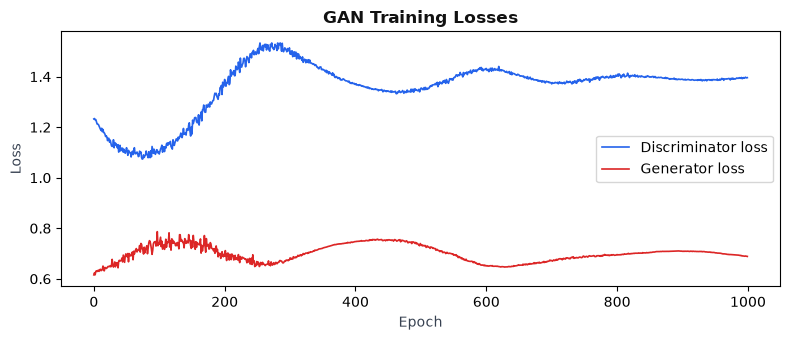

Training curves plotted.


In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(loss_D_history, label='Discriminator loss', color='#2563eb', lw=1.2)
ax.plot(loss_G_history, label='Generator loss',     color='#dc2626', lw=1.2)
ax.set_xlabel('Epoch', color='#374151')
ax.set_ylabel('Loss',  color='#374151')
ax.set_title('GAN Training Losses', color='#111111', fontweight='bold')
ax.legend()
ax.set_facecolor('white')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()
print('Training curves plotted.')

## Part 4 — Generation: Comparing Real and Generated Distributions

We sample from the trained generator and compare the generated distribution to the real $\mathcal{N}(3, 0.5^2)$ distribution.

Real data  — mean: 3.017, std: 0.499
Generated  — mean: 2.864, std: 0.179


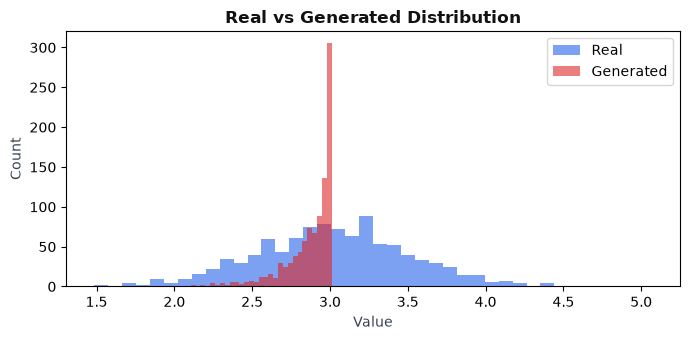

Distribution comparison plotted.


In [4]:
G.eval()
with torch.no_grad():
    z_test    = sample_noise(1000)
    x_gen     = G(z_test).squeeze().numpy()
    x_real_np = sample_real(1000).squeeze().numpy()

print(f'Real data  — mean: {x_real_np.mean():.3f}, std: {x_real_np.std():.3f}')
print(f'Generated  — mean: {x_gen.mean():.3f}, std: {x_gen.std():.3f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(x_real_np, bins=40, alpha=0.6, color='#2563eb', label='Real')
ax.hist(x_gen,     bins=40, alpha=0.6, color='#dc2626', label='Generated')
ax.set_xlabel('Value', color='#374151')
ax.set_ylabel('Count', color='#374151')
ax.set_title('Real vs Generated Distribution', color='#111111', fontweight='bold')
ax.legend()
ax.set_facecolor('white')
fig.patch.set_facecolor('white')
plt.tight_layout()
plt.show()
print('Distribution comparison plotted.')

The generated distribution should closely match the real $\mathcal{N}(3, 0.5^2)$ distribution — mean near 3.0 and standard deviation near 0.5.

## Summary

This notebook demonstrated:
1. Forward pass trace — discriminator and generator losses computed step by step, matching the Note 31 worked example
2. Full GAN training loop — alternating discriminator and generator updates with the non-saturating generator loss
3. Training curves — adversarial dynamics between $\mathcal{L}_D$ and $\mathcal{L}_G$ over 1000 epochs
4. Generation — trained generator reproduces the real $\mathcal{N}(3, 0.5^2)$ distribution from noise